# Amazon Summary Notebook

This notebook reads persistent state from `../state/state.sqlite3` and shows:

1. Summary data table (`monthly_summaries`)
2. Category totals table (all time)
3. Trend chart for up to the top 5 largest categories

In [1]:
from pathlib import Path
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd

state_dir = Path('../state')
db_path = state_dir / 'state.sqlite3'

# Keep the trend chart readable by limiting the number of category lines.
MAX_TOP_CATEGORIES = 5

if not db_path.exists():
    raise FileNotFoundError(f'State database not found at: {db_path.resolve()}')

with sqlite3.connect(db_path) as conn:
    monthly_summaries = pd.read_sql_query(
        '''
        SELECT summary_month_start, category, amount_total
        FROM monthly_summaries
        ORDER BY summary_month_start, category
        ''',
        conn,
    )

if not monthly_summaries.empty:
    monthly_summaries['summary_month_start'] = pd.to_datetime(
        monthly_summaries['summary_month_start']
    )

## Summary Data Table

In [2]:
if monthly_summaries.empty:
    print('No summary data found in monthly_summaries.')
else:
    monthly_summaries

## Category Totals (All Time)

In [3]:
if monthly_summaries.empty:
    category_totals = pd.DataFrame(columns=['category', 'amount_total_all_time'])
else:
    category_totals = (
        monthly_summaries.groupby('category', as_index=False)['amount_total']
        .sum()
        .rename(columns={'amount_total': 'amount_total_all_time'})
        .sort_values('amount_total_all_time', ascending=False)
    )

category_totals

,category,amount_total_all_time
3,Medical,1199.94
1,Food,975.46
2,Household,537.35
0,Electronics,78.38
4,Tools,30.51


In [4]:
from IPython.display import Markdown, display

display(Markdown(f"## Trend Over Time (Top {MAX_TOP_CATEGORIES} Categories)"))

## Trend Over Time (Top 5 Categories)

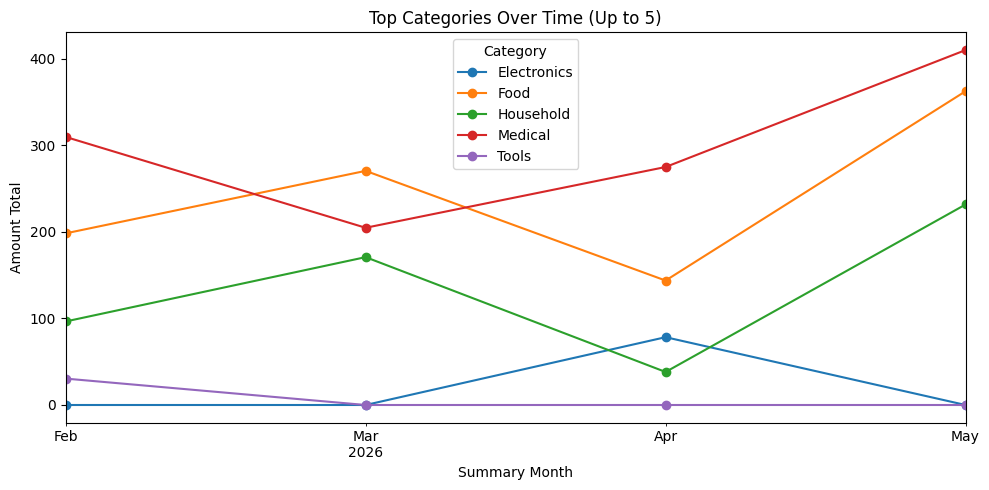

In [5]:
if monthly_summaries.empty or category_totals.empty:
    print('Not enough data to plot trends.')
else:
    top_categories = category_totals.head(MAX_TOP_CATEGORIES)['category'].tolist()
    trend = (
        monthly_summaries[monthly_summaries['category'].isin(top_categories)]
        .pivot_table(
            index='summary_month_start',
            columns='category',
            values='amount_total',
            aggfunc='sum',
            fill_value=0.0,
        )
        .sort_index()
    )

    ax = trend.plot(figsize=(10, 5), marker='o')
    ax.set_title(f'Top Categories Over Time (Up to {MAX_TOP_CATEGORIES})')
    ax.set_xlabel('Summary Month')
    ax.set_ylabel('Amount Total')
    ax.legend(title='Category', loc='best')
    plt.tight_layout()
    plt.show()